# Business Understanding

## Latar Belakang
Harga laptop dapat berbeda-beda bergantung pada spesifikasi dan karakteristiknya, seperti merek, model, prosesor, RAM, kapasitas dan jenis penyimpanan, kartu grafis, ukuran layar, serta status produk. Perbedaan tersebut dapat menyulitkan calon pembeli dalam memperkirakan apakah harga sebuah laptop tergolong wajar.

Dalam proyek ini, data spesifikasi laptop digunakan untuk membangun model yang memperkirakan harga laptop. Hasil model diharapkan dapat menjadi gambaran awal mengenai hubungan antara karakteristik laptop dan harganya.

## Rumusan Masalah
1. Seberapa baik karakteristik laptop dalam data dapat digunakan untuk memperkirakan harga laptop?
2. Di antara model regresi yang dibandingkan, model mana yang memberikan hasil prediksi terbaik?
3. Seberapa besar rata-rata selisih prediksi harga terhadap harga sebenarnya?

## Tujuan
Proyek ini bertujuan membangun dan membandingkan beberapa model regresi untuk memprediksi kolom `Final Price` berdasarkan fitur laptop yang tersedia. Model terbaik dipilih berdasarkan hasil validasi silang pada data latih, kemudian dievaluasi menggunakan data uji.

## Metode dan Metrik
Metode yang digunakan adalah supervised learning dengan pendekatan regresi, karena target yang diprediksi berupa nilai numerik, yaitu harga laptop. Target harga ditransformasikan menggunakan `log1p` untuk membantu pemodelan.

Kinerja model dinilai menggunakan:
- **R²**, untuk mengukur proporsi variasi target yang dapat dijelaskan model.
- **RMSE**, untuk mengukur besar kesalahan prediksi. Karena target menggunakan transformasi log, RMSE pada evaluasi ini berada pada skala log.
- **MAE**, yang dihitung setelah prediksi dikembalikan ke skala harga agar besar kesalahan lebih mudah dipahami dalam satuan harga.

Hasil evaluasi digunakan untuk memilih model yang paling sesuai dengan data dan tujuan proyek.

#Collecting Data

In [182]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("juanmerinobermejo/laptops-price-dataset")

# print("Path to dataset files:", path)

#Import library

In [183]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV #model evaluasi
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler #preprocess
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error #metric evaluasi
from sklearn.linear_model import LinearRegression, Ridge #algoritma
from sklearn.tree import DecisionTreeRegressor #algoritma
from lightgbm import LGBMRegressor #algoritma
from xgboost import XGBRegressor #algoritma

#Overview Data

In [184]:
df = pd.read_csv('laptops.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   object 
 1   Status        2160 non-null   object 
 2   Brand         2160 non-null   object 
 3   Model         2160 non-null   object 
 4   CPU           2160 non-null   object 
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   object 
 8   GPU           789 non-null    object 
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   object 
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), object(8)
memory usage: 202.6+ KB


In [185]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [186]:
df.duplicated().sum()

np.int64(0)

In [187]:
df.isna().sum()

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

In [188]:
df.describe()

,RAM,Storage,Screen,Final Price
count,2160.000000,2160.000000,2156.000000,2160.000000
mean,15.413889,596.294444,15.168112,1312.638509
std,9.867815,361.220506,1.203329,911.475417
min,4.000000,0.000000,10.100000,201.050000
25%,8.000000,256.000000,14.000000,661.082500
50%,16.000000,512.000000,15.600000,1031.945000
75%,16.000000,1000.000000,15.600000,1708.970000
max,128.000000,4000.000000,18.000000,7150.470000


#Cleaning Data

## Standarized Brand Names

In [189]:
df['Brand'] = df['Brand'].str.strip().str.title()
df['Brand'] = df['Brand'].replace({'Asus': 'ASUS', 'Apple': 'Apple', 'Hp': 'HP'})

## Clean GPU Spacing

In [190]:
df['GPU'] = df['GPU'].str.replace(r'([A-Za-z])(\d)', r'\1 \2', regex=True).str.strip()
df['GPU'] = df['GPU'].fillna('Integrated')

## Missing Storage Types

In [191]:
df['Storage type'] = df['Storage type'].fillna('Unknown')

## Missing Screen Size

In [192]:
df['Screen'] = df['Screen'].fillna(df['Screen'].mode()[0])

## Convert Data Types

In [193]:
df['RAM'] = pd.to_numeric(df['RAM'], errors='coerce')
df['Storage'] = pd.to_numeric(df['Storage'], errors='coerce')
df['Final Price'] = pd.to_numeric(df['Final Price'], errors='coerce')
df['Touch'] = df['Touch'].map({'Yes': 1, 'No': 0})

In [194]:
df.isna().sum()

Laptop          0
Status          0
Brand           0
Model           0
CPU             0
RAM             0
Storage         0
Storage type    0
GPU             0
Screen          0
Touch           0
Final Price     0
dtype: int64

In [195]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01


In [196]:
df.describe()

,RAM,Storage,Screen,Touch,Final Price
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,15.413889,596.294444,15.168912,0.105093,1312.638509
std,9.867815,361.220506,1.202357,0.306744,911.475417
min,4.000000,0.000000,10.100000,0.000000,201.050000
25%,8.000000,256.000000,14.000000,0.000000,661.082500
50%,16.000000,512.000000,15.600000,0.000000,1031.945000
75%,16.000000,1000.000000,15.600000,0.000000,1708.970000
max,128.000000,4000.000000,18.000000,1.000000,7150.470000


#EDA

Ukuran dataset: (2160, 12)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   object 
 1   Status        2160 non-null   object 
 2   Brand         2160 non-null   object 
 3   Model         2160 non-null   object 
 4   CPU           2160 non-null   object 
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2160 non-null   object 
 8   GPU           2160 non-null   object 
 9   Screen        2160 non-null   float64
 10  Touch         2160 non-null   int64  
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(3), object(7)
memory usage: 202.6+ KB


,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01


Jumlah baris duplikat: 0


,Jumlah Missing Value,Persentase Missing (%)
Laptop,0,0.0
Status,0,0.0
Brand,0,0.0
Model,0,0.0
CPU,0,0.0
RAM,0,0.0
Storage,0,0.0
Storage type,0,0.0
GPU,0,0.0
Screen,0,0.0


,count,mean,std,min,25%,50%,75%,max
RAM,2160.0,15.413889,9.867815,4.00,8.0000,16.000,16.00,128.00
Storage,2160.0,596.294444,361.220506,0.00,256.0000,512.000,1000.00,4000.00
Screen,2160.0,15.168912,1.202357,10.10,14.0000,15.600,15.60,18.00
Touch,2160.0,0.105093,0.306744,0.00,0.0000,0.000,0.00,1.00
Final Price,2160.0,1312.638509,911.475417,201.05,661.0825,1031.945,1708.97,7150.47


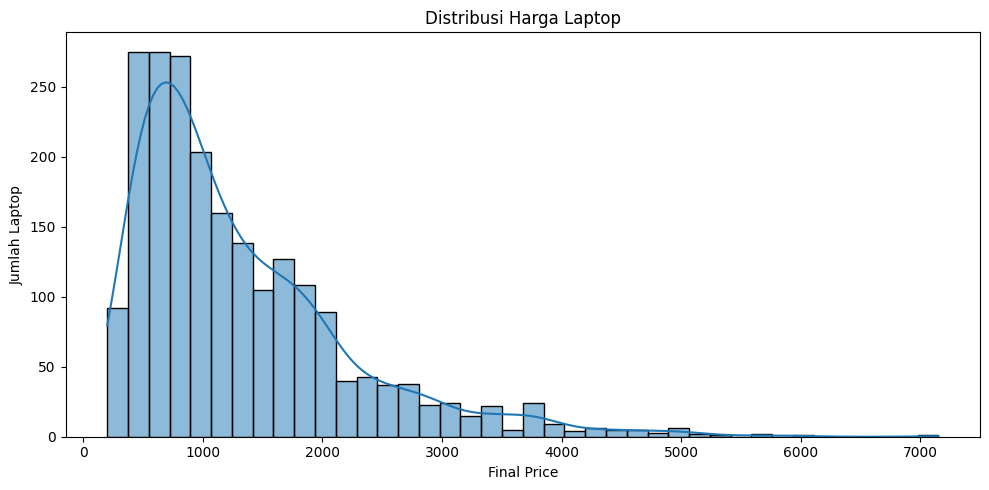

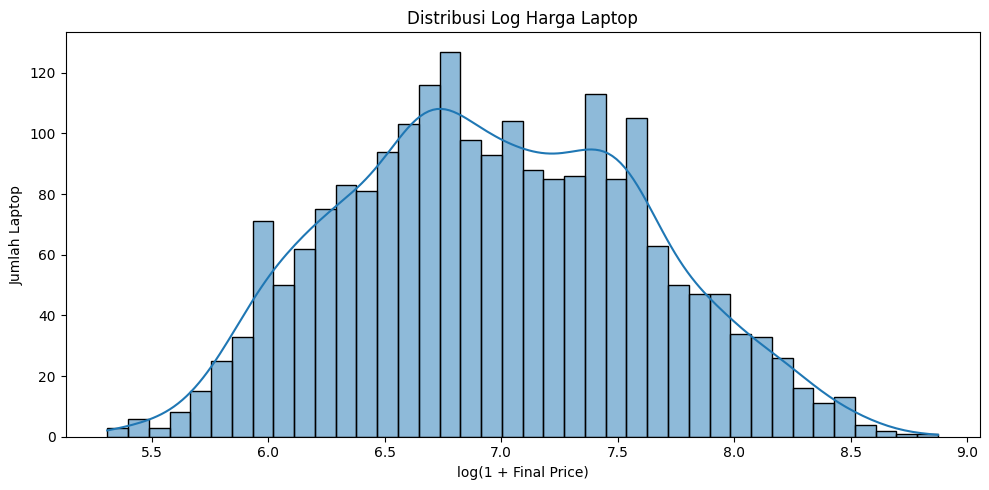

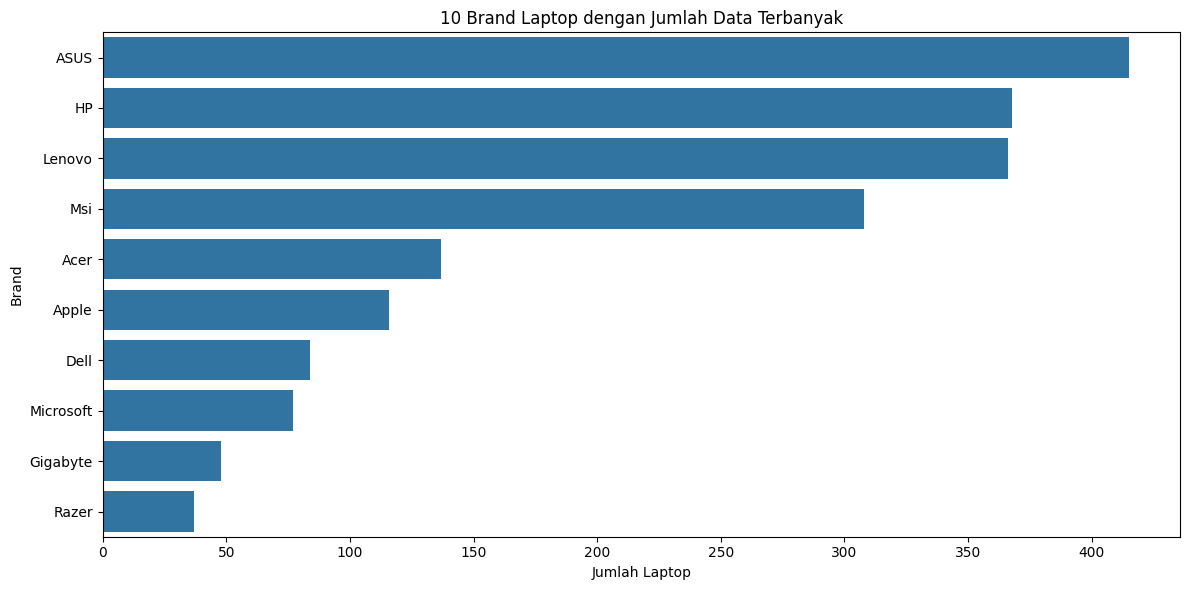

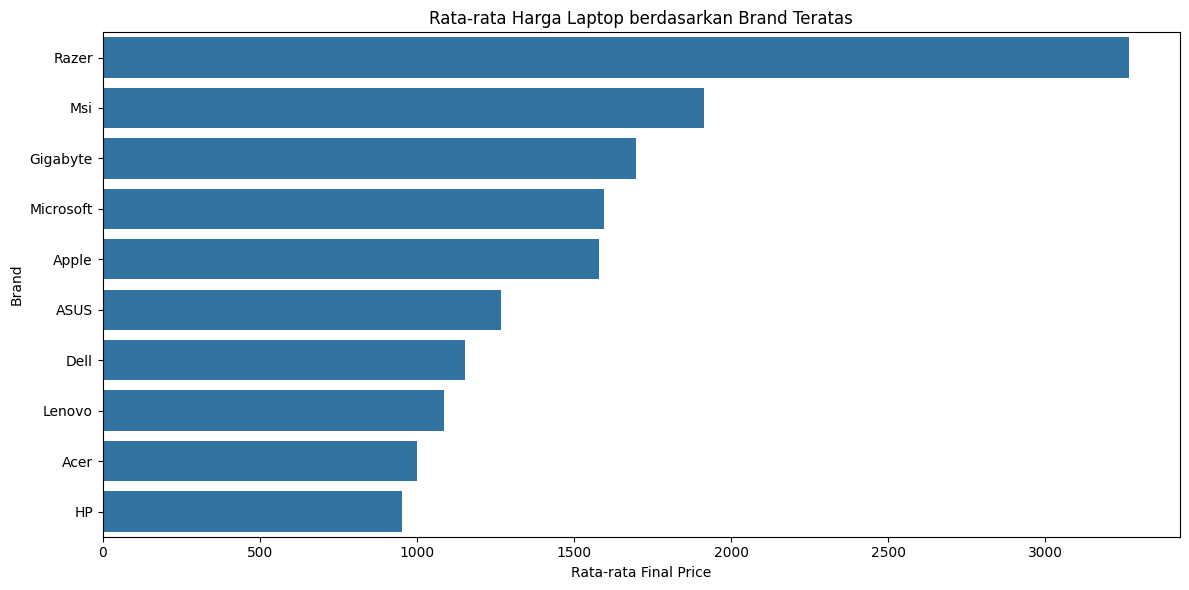

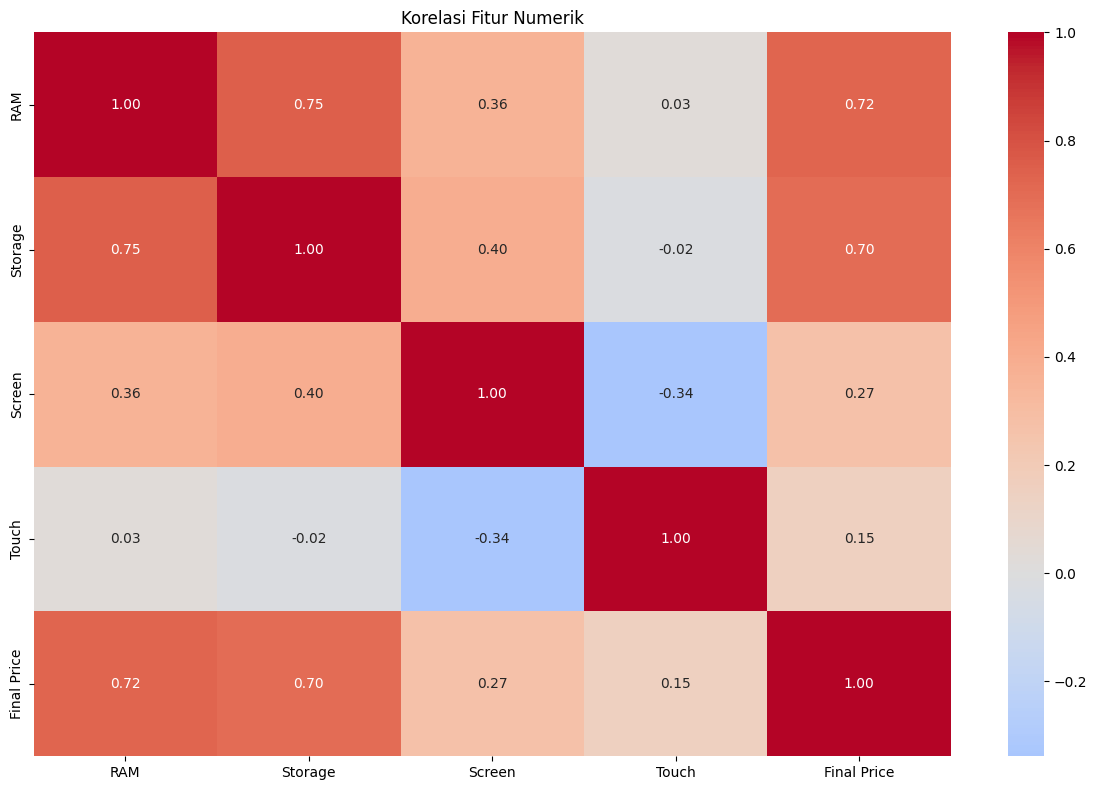

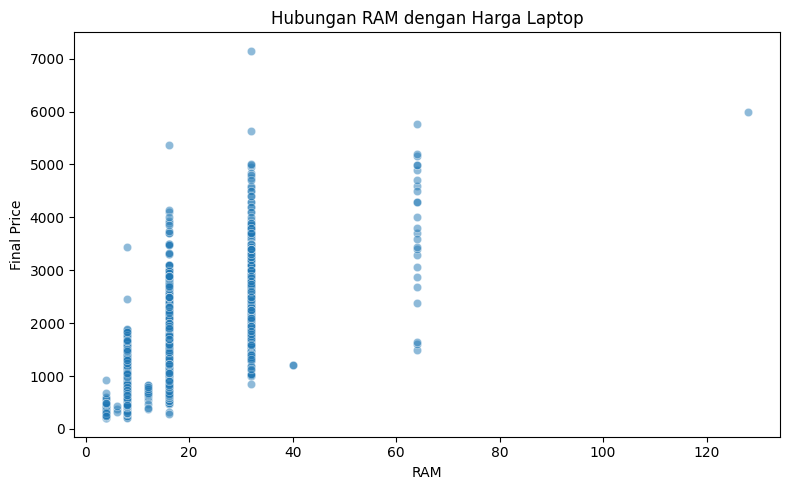

In [197]:
# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# 1. Melihat ukuran dataset dan tipe data
df_eda=df.copy()
print("Ukuran dataset:", df_eda.shape)
print("\nInformasi dataset:")
df_eda.info()

# 2. Melihat contoh data
display(df_eda.head())

# 3. Memeriksa data duplikat dan missing value
print("Jumlah baris duplikat:", df_eda.duplicated().sum())

missing_summary = pd.DataFrame({
    "Jumlah Missing Value": df_eda.isna().sum(),
    "Persentase Missing (%)": (df_eda.isna().mean() * 100).round(2)
}).sort_values("Jumlah Missing Value", ascending=False)

display(missing_summary)

# 4. Statistik deskriptif untuk kolom numerik
display(df_eda.describe().T)

# 5. Distribusi harga laptop
plt.figure(figsize=(10, 5))
sns.histplot(data=df_eda, x="Final Price", bins=40, kde=True)
plt.title("Distribusi Harga Laptop")
plt.xlabel("Final Price")
plt.ylabel("Jumlah Laptop")
plt.tight_layout()
plt.show()

# 6. Distribusi harga setelah transformasi log (membantu melihat kemencengan data)
plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(df_eda["Final Price"].dropna()), bins=40, kde=True)
plt.title("Distribusi Log Harga Laptop")
plt.xlabel("log(1 + Final Price)")
plt.ylabel("Jumlah Laptop")
plt.tight_layout()
plt.show()

# 7. Jumlah laptop berdasarkan brand (10 brand dengan jumlah terbanyak)
if "Brand" in df_eda.columns:
    plt.figure(figsize=(12, 6))
    brand_counts = df_eda["Brand"].value_counts().head(10)
    sns.barplot(x=brand_counts.values, y=brand_counts.index)
    plt.title("10 Brand Laptop dengan Jumlah Data Terbanyak")
    plt.xlabel("Jumlah Laptop")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()

# 8. Rata-rata harga untuk 10 brand dengan jumlah data terbanyak
if "Brand" in df_eda.columns:
    top_brands = df_eda["Brand"].value_counts().head(10).index
    brand_price = (
        df_eda[df_eda["Brand"].isin(top_brands)]
        .groupby("Brand", as_index=False)["Final Price"]
        .mean()
        .sort_values("Final Price", ascending=False)
    )
    plt.figure(figsize=(12, 6))
    sns.barplot(data=brand_price, x="Final Price", y="Brand")
    plt.title("Rata-rata Harga Laptop berdasarkan Brand Teratas")
    plt.xlabel("Rata-rata Final Price")
    plt.ylabel("Brand")
    plt.tight_layout()
    plt.show()

# 9. Korelasi antarfitur numerik
numeric_df_eda = df_eda.select_dtypes(include=np.number)
if numeric_df_eda.shape[1] > 1:
    plt.figure(figsize=(12, 8))
    sns.heatmap(numeric_df_eda.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title("Korelasi Fitur Numerik")
    plt.tight_layout()
    plt.show()

# 10. Hubungan RAM dan harga laptop
if "RAM" in df_eda.columns and "Final Price" in df_eda.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df_eda, x="RAM", y="Final Price", alpha=0.5)
    plt.title("Hubungan RAM dengan Harga Laptop")
    plt.xlabel("RAM")
    plt.ylabel("Final Price")
    plt.tight_layout()
    plt.show()


#Preprocessing

##Feature Engineering

###Mengekstrak informasi dari fitur CPU

In [198]:
def categorize_cpu(cpu_name):
    cpu_name = str(cpu_name).lower()
    if 'i9' in cpu_name or 'ryzen 9' in cpu_name or 'm1 max' in cpu_name or 'm2 max' in cpu_name or 'm3 max' in cpu_name:
        return 'High-End'
    elif 'i7' in cpu_name or 'ryzen 7' in cpu_name or 'm1 pro' in cpu_name or 'm2 pro' in cpu_name or 'm3 pro' in cpu_name or 'm1' in cpu_name or 'm2' in cpu_name or 'm3' in cpu_name:
        return 'Mid-High'
    elif 'i5' in cpu_name or 'ryzen 5' in cpu_name:
        return 'Medium'
    elif 'i3' in cpu_name or 'ryzen 3' in cpu_name:
        return 'Entry-Medium'
    else:
        return 'Budget'

df['CPU_Class'] = df['CPU'].apply(categorize_cpu)

###Menyederhanakan Brand GPU

In [199]:
def categorize_gpu(gpu_name):
    gpu_name = str(gpu_name).lower()
    if 'rtx' in gpu_name:
        return 'NVIDIA RTX'
    elif 'gtx' in gpu_name:
        return 'NVIDIA GTX'
    elif 'radeon' in gpu_name or 'rx' in gpu_name:
        return 'AMD Radeon'
    elif 'intel' in gpu_name or 'integrated' in gpu_name:
        return 'Intel Integrated'
    elif 'apple' in gpu_name:
        return 'Apple Silicon'
    else:
        return 'Other'

df['GPU_Class'] = df['GPU'].apply(categorize_gpu)

###Rasio RAM terhadap Storage

In [200]:
df['RAM_Storage_Ratio'] = df['RAM'] / (df['Storage'] + 1)

In [201]:
df[['CPU', 'CPU_Class', 'GPU', 'GPU_Class', 'RAM_Storage_Ratio']].head()

,CPU,CPU_Class,GPU,GPU_Class,RAM_Storage_Ratio
0,Intel Core i5,Medium,Integrated,Intel Integrated,0.015595
1,Intel Celeron,Budget,Integrated,Intel Integrated,0.031128
2,Intel Core i3,Entry-Medium,Integrated,Intel Integrated,0.031128
3,Intel Core i7,Mid-High,RTX 3050,NVIDIA RTX,0.015984
4,Intel Core i5,Medium,Integrated,Intel Integrated,0.031189


In [202]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price,CPU_Class,GPU_Class,RAM_Storage_Ratio
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,ASUS,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,0,1009.00,Medium,Intel Integrated,0.015595
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,0,299.00,Budget,Intel Integrated,0.031128
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,ASUS,ExpertBook,Intel Core i3,8,256,SSD,Integrated,15.6,0,789.00,Entry-Medium,Intel Integrated,0.031128
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,Msi,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,0,1199.00,Mid-High,NVIDIA RTX,0.015984
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,Integrated,15.6,0,669.01,Medium,Intel Integrated,0.031189


In [203]:
df.drop(columns=['Laptop'], inplace=True)

###Split train validation

In [204]:
X = df.drop(columns=['Final Price']).copy()
y = np.log1p(df['Final Price'])

In [205]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [206]:
X_train = X_train.reset_index(drop=True)
X_test   = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test   = y_test.reset_index(drop=True)

print(f"X_train : {X_train.shape}")
print(f"X_test   : {X_test.shape}")

X_train : (1728, 13)
X_test   : (432, 13)


In [207]:
X_train.head()

,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,CPU_Class,GPU_Class,RAM_Storage_Ratio
0,Refurbished,ASUS,F515,Intel Core i7,8,512,SSD,Integrated,15.6,0,Mid-High,Intel Integrated,0.015595
1,New,HP,Chromebook,Intel Celeron,4,64,eMMC,Integrated,14.0,1,Budget,Intel Integrated,0.061538
2,New,ASUS,ROG,AMD Ryzen 7,16,512,SSD,RTX 3050,15.6,0,Mid-High,NVIDIA RTX,0.031189
3,Refurbished,ASUS,ROG,Intel Core i7,16,1000,SSD,RTX 2070,15.6,0,Mid-High,NVIDIA RTX,0.015984
4,Refurbished,Gigabyte,Aorus,Intel Core i7,16,512,SSD,RTX 2070,15.6,0,Mid-High,NVIDIA RTX,0.031189


In [208]:
y_train.head()

0    6.551080
1    5.991465
2    6.814532
3    7.148416
4    6.953627
Name: Final Price, dtype: float64

In [209]:
categorical_cols = X_train.select_dtypes(exclude=['int64', 'float64']).columns
numerical_cols = X_train.select_dtypes(exclude=['object']).columns

print(f"Kolom Categorik\n{categorical_cols}")
print(f"Kolom Numerik\n{numerical_cols}")

Kolom Categorik
Index(['Status', 'Brand', 'Model', 'CPU', 'Storage type', 'GPU', 'CPU_Class',
       'GPU_Class'],
      dtype='object')
Kolom Numerik
Index(['RAM', 'Storage', 'Screen', 'Touch', 'RAM_Storage_Ratio'], dtype='object')


##Encoding

###Target Encoding

In [210]:
train_temp = X_train.copy()
train_temp['Final Price'] = y_train

In [211]:
def oof_target_encoding(X_train, y_train, X_val, cols, n_splits=5, smoothing=10, random_state=42):

    X_train = X_train.copy()
    X_val = X_val.copy()

    global_mean = y_train.mean()

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for col in cols:

        oof_encoded = np.zeros(len(X_train))

        for train_idx, val_idx in kf.split(X_train):

            X_tr = X_train.iloc[train_idx]
            y_tr = y_train.iloc[train_idx]

            temp = pd.DataFrame({col: X_tr[col], 'target': y_tr})

            stats = temp.groupby(col)['target'].agg(mean='mean', count='count')

            encoded_map = (stats['count'] * stats['mean']+ smoothing * global_mean) / (stats['count'] + smoothing)

            oof_encoded[val_idx] = (X_train.iloc[val_idx][col].map(encoded_map).fillna(global_mean))

        X_train[f'{col}_te'] = oof_encoded

        # Encoding untuk TEST menggunakan seluruh training set
        temp_full = pd.DataFrame({col: X_train[col], 'target': y_train})

        stats_full = temp_full.groupby(col)['target'].agg(mean='mean', count='count')

        encoded_map_full = (stats_full['count'] * stats_full['mean']+ smoothing * global_mean) / (stats_full['count'] + smoothing)

        X_val[f'{col}_te'] = (X_val[col].map(encoded_map_full).fillna(global_mean))

    return X_train, X_val

In [212]:
cols_target_encode = ['Brand', 'Model', 'CPU', 'GPU']

X_train, X_test = oof_target_encoding(X_train, y_train, X_test, cols=cols_target_encode, n_splits=5, smoothing=10)

In [213]:
X_train.drop(columns=['Brand'], inplace=True)
X_test.drop(columns=['Brand'], inplace=True)
X_train.drop(columns=['Model'], inplace=True)
X_test.drop(columns=['Model'], inplace=True)
X_train.drop(columns=['CPU'], inplace=True)
X_test.drop(columns=['CPU'], inplace=True)
X_train.drop(columns=['GPU'], inplace=True)
X_test.drop(columns=['GPU'], inplace=True)

###Label Encoding

In [214]:
le = LabelEncoder()

# Status
le.fit(X_train['Status'])
X_train['Status'] = le.transform(X_train['Status'])
X_test['Status'] = le.transform(X_test['Status'])

###OHE

In [215]:
ohe_cols = ['Storage type', 'GPU_Class']
ohe_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_train = ohe_encoder.fit_transform(X_train[ohe_cols])

encoded_train_df = pd.DataFrame(encoded_train, columns=ohe_encoder.get_feature_names_out(ohe_cols), index=X_train.index)

X_train = pd.concat([X_train.drop(columns=ohe_cols), encoded_train_df], axis=1)

encoded_test = ohe_encoder.transform(X_test[ohe_cols])

encoded_test_df = pd.DataFrame(encoded_test, columns=ohe_encoder.get_feature_names_out(ohe_cols), index=X_test.index)

X_test = pd.concat([X_test.drop(columns=ohe_cols), encoded_test_df], axis=1)

###Ordinal Encoding

In [216]:
df['CPU_Class'].value_counts()

CPU_Class
Mid-High        1012
Medium           692
Entry-Medium     174
Budget           143
High-End         139
Name: count, dtype: int64

In [217]:
ordinalencode = OrdinalEncoder()
kategori_cpu = [['Budget', 'Entry-Medium', 'Medium', 'Mid-High', 'High-End']]
X_train['CPU_Class_Encoded'] = ordinalencode.fit_transform(X_train[['CPU_Class']])
X_test['CPU_Class_Encoded'] = ordinalencode.transform(X_test[['CPU_Class']])

X_train.drop(columns=['CPU_Class'], inplace=True)
X_test.drop(columns=['CPU_Class'], inplace=True)

In [218]:
X_train.head()

,Status,RAM,Storage,Screen,Touch,RAM_Storage_Ratio,Brand_te,Model_te,CPU_te,GPU_te,Storage type_SSD,Storage type_Unknown,Storage type_eMMC,GPU_Class_AMD Radeon,GPU_Class_Intel Integrated,GPU_Class_NVIDIA GTX,GPU_Class_NVIDIA RTX,GPU_Class_Other,CPU_Class_Encoded
0,1,8,512,15.6,0,0.015595,6.899490,6.618526,7.296797,6.681707,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0
1,0,4,64,14.0,1,0.061538,6.664933,6.301956,6.023743,6.681614,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0,16,512,15.6,0,0.031189,6.899490,7.557502,6.945048,7.186843,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0
3,1,16,1000,15.6,0,0.015984,6.899490,7.557502,7.296797,7.126935,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0
4,1,16,512,15.6,0,0.031189,7.234615,7.072320,7.300004,7.116021,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0


In [219]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1728, 19)
(432, 19)
(1728,)
(432,)


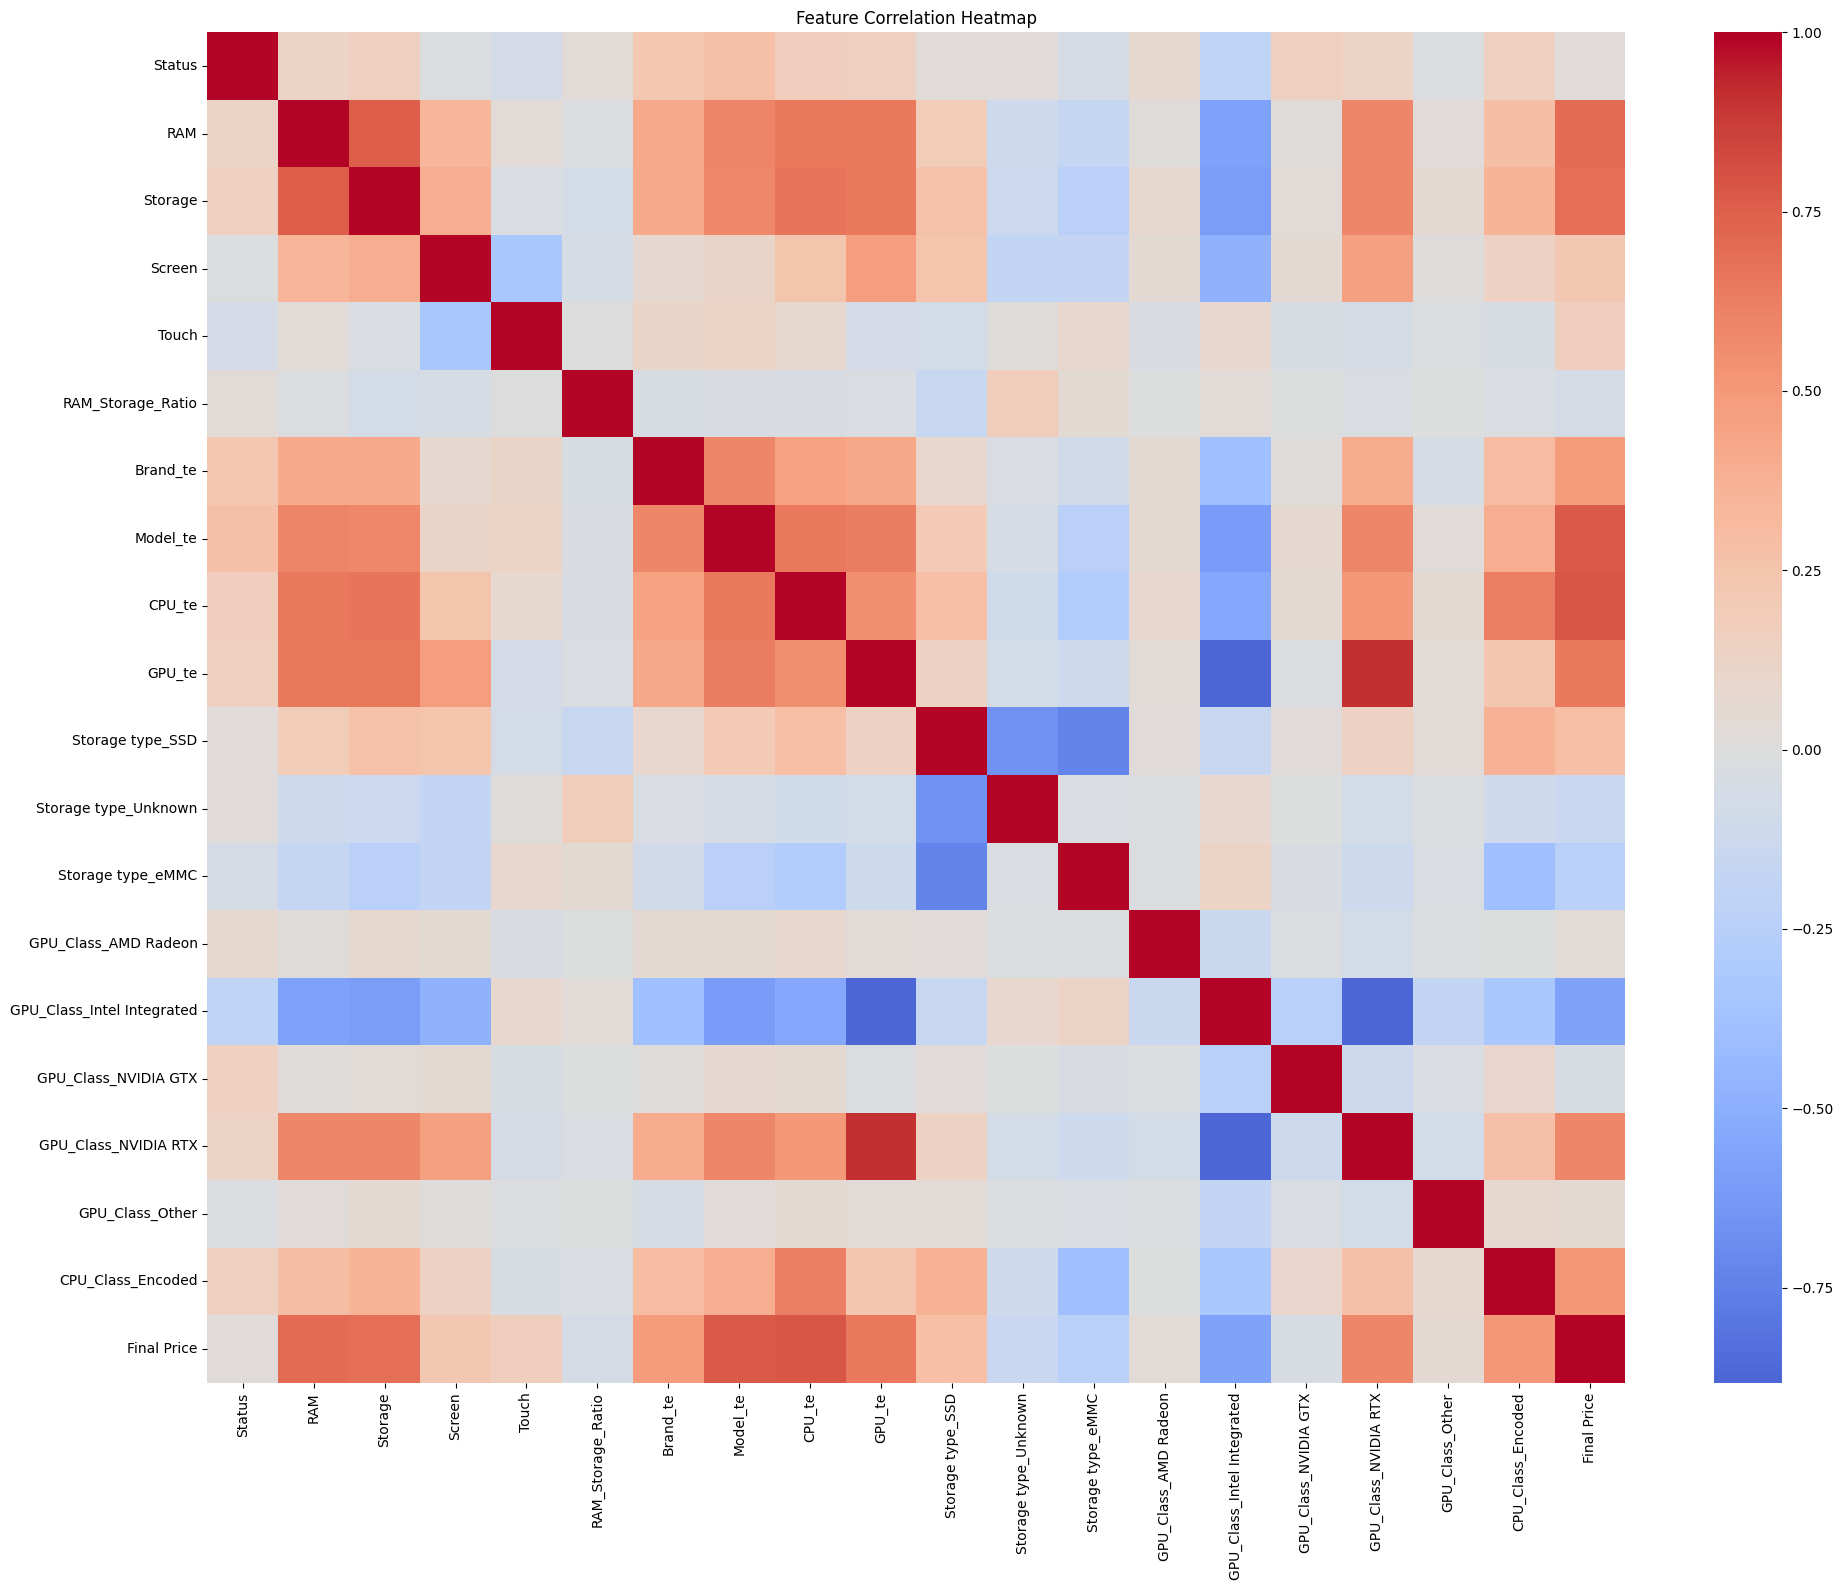

In [220]:
df_corr = X_train.copy()
df_corr['Final Price'] = y_train

corr_matrix = df_corr.corr()

plt.figure(figsize=(20,16))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

##Feature Selection

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

# Tentukan jumlah fitur yang ingin dipilih
k_fitur = 15

selector = SelectKBest(score_func=f_regression, k=k_fitur)
selector.fit(X_train, y_train)

# Lihat skor dan fitur yang terpilih
hasil_seleksi = pd.DataFrame({
    "Fitur": X_train.columns,
    "F_Score": selector.scores_,
    "P_Value": selector.pvalues_,
    "Terpilih": selector.get_support()
}).sort_values("F_Score", ascending=False)

display(hasil_seleksi)

# Terapkan pilihan fitur yang sama pada data train dan test
fitur_terpilih = X_train.columns[selector.get_support()]

X_train_selected = X_train.loc[:, fitur_terpilih].copy()
X_test_selected = X_test.loc[:, fitur_terpilih].copy()

print("Fitur terpilih:", fitur_terpilih.tolist())
print("Ukuran X_train setelah seleksi:", X_train_selected.shape)
print("Ukuran X_test setelah seleksi:", X_test_selected.shape)

,Fitur,F_Score,P_Value,Terpilih
8,CPU_te,2683.561165,0.000000e+00,True
7,Model_te,2443.959447,0.000000e+00,True
1,RAM,1702.873712,1.464043e-259,True
2,Storage,1527.959763,6.334561e-240,True
9,GPU_te,1248.878143,2.715092e-206,True
16,GPU_Class_NVIDIA RTX,908.817904,9.385291e-161,True
14,GPU_Class_Intel Integrated,843.277509,2.654978e-151,True
18,CPU_Class_Encoded,604.197819,1.207737e-114,True
6,Brand_te,546.905631,2.681343e-105,True
10,Storage type_SSD,150.100521,3.759546e-33,True


Fitur terpilih: ['RAM', 'Storage', 'Screen', 'Touch', 'Brand_te', 'Model_te', 'CPU_te', 'GPU_te', 'Storage type_SSD', 'Storage type_Unknown', 'Storage type_eMMC', 'GPU_Class_Intel Integrated', 'GPU_Class_NVIDIA RTX', 'GPU_Class_Other', 'CPU_Class_Encoded']
Ukuran X_train setelah seleksi: (1728, 15)
Ukuran X_test setelah seleksi: (432, 15)


#Model Evaluation

In [223]:
results = {}
def evaluate_model(model_name, X_train, y_train, X_test, y_test, model):
  kf = KFold(n_splits=5, shuffle=True, random_state=42)

  cross_val_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
  cross_val_rmse = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')

  print(f'\n===== {model_name} =====')
  print(f'Cross Validation R2: {cross_val_r2.mean():.4f}')
  print(f'Cross Validation RMSE: {-cross_val_rmse.mean():.4f}')

  model.fit(X_train, y_train)
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  r2_train = r2_score(y_train, y_train_pred)
  rmse_train = np.sqrt(mean_squared_error((y_train), (y_train_pred)))
  r2_test = r2_score(y_test, y_test_pred)
  rmse_test = np.sqrt(mean_squared_error((y_test), (y_test_pred)))

  results[model_name] = {
    'model': model,
    'r2_train': r2_train,
    'rmse_train': rmse_train,
    'r2_test': r2_test,
    'rmse_test': rmse_test
  }
  print(f'R2 Train: {r2_train:.4f}')
  print(f'RMSE Train: {rmse_train:.4f}')
  print(f'R2 Test: {r2_test:.4f}')
  print(f'RMSE Test: {rmse_test:.4f}')

In [224]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

evaluate_model('Linear Regression', X_train_selected, y_train, X_test_selected, y_test, model)


===== Linear Regression =====
Cross Validation R2: 0.7875
Cross Validation RMSE: 0.2957
R2 Train: 0.7925
RMSE Train: 0.2934
R2 Test: 0.8054
RMSE Test: 0.2912


In [225]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

evaluate_model('Ridge Regression', X_train_selected, y_train, X_test_selected, y_test, model)


===== Ridge Regression =====
Cross Validation R2: 0.7875
Cross Validation RMSE: 0.2957
R2 Train: 0.7925
RMSE Train: 0.2934
R2 Test: 0.8054
RMSE Test: 0.2912


In [226]:
model = Pipeline([
    ('model', DecisionTreeRegressor(random_state=42))
])

evaluate_model('Decision Tree Regressor', X_train_selected, y_train, X_test_selected, y_test, model)


===== Decision Tree Regressor =====
Cross Validation R2: 0.7096
Cross Validation RMSE: 0.3452
R2 Train: 0.9806
RMSE Train: 0.0896
R2 Test: 0.6712
RMSE Test: 0.3785


In [227]:
model = Pipeline([
    ('model', XGBRegressor(random_state=42))
])

evaluate_model('XGB Regressor', X_train_selected, y_train, X_test_selected, y_test, model)


===== XGB Regressor =====
Cross Validation R2: 0.8089
Cross Validation RMSE: 0.2801
R2 Train: 0.9669
RMSE Train: 0.1172
R2 Test: 0.8235
RMSE Test: 0.2773


In [228]:
model = Pipeline([
    ('model', LGBMRegressor(random_state=42))
])

evaluate_model('LGBM', X_train_selected, y_train, X_test_selected, y_test, model)


===== LGBM =====
Cross Validation R2: 0.8369
Cross Validation RMSE: 0.2592
R2 Train: 0.9236
RMSE Train: 0.1781
R2 Test: 0.8527
RMSE Test: 0.2534


In [229]:
!pip install catboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [230]:
from catboost import CatBoostRegressor

In [231]:
model = Pipeline([
    ('model', CatBoostRegressor(verbose=0, random_state=42))
])

evaluate_model('CatBoost', X_train_selected, y_train, X_test_selected, y_test, model)


===== CatBoost =====
Cross Validation R2: 0.8383
Cross Validation RMSE: 0.2579
R2 Train: 0.9307
RMSE Train: 0.1695
R2 Test: 0.8591
RMSE Test: 0.2477


In [232]:
summary = pd.DataFrame({
    name: {
        'Train R2': f"{values['r2_train']:.4f}",
        'Train RMSE': f"{values['rmse_train']:.4f}",
        'Test R2': f"{values['r2_test']:.4f}",
        'Test RMSE': f"{values['rmse_test']:.4f}"
    }
    for name, values in results.items()
}).T.sort_values(by='Test R2', ascending=False)

print(summary)

                        Train R2 Train RMSE Test R2 Test RMSE
CatBoost                  0.9307     0.1695  0.8591    0.2477
LGBM                      0.9236     0.1781  0.8527    0.2534
XGB Regressor             0.9669     0.1172  0.8235    0.2773
Linear Regression         0.7925     0.2934  0.8054    0.2912
Ridge Regression          0.7925     0.2934  0.8054    0.2912
Decision Tree Regressor   0.9806     0.0896  0.6712    0.3785


In [233]:
best_model = CatBoostRegressor(random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cross_val_r2 = cross_val_score(best_model, X_train_selected, y_train, cv=kf, scoring='r2')
cross_val_rmse = cross_val_score(best_model, X_train_selected, y_train, cv=kf, scoring='neg_root_mean_squared_error')

print(f'Cross Validation R2: {cross_val_r2.mean():.4f}')
print(f'Cross Validation RMSE: {-cross_val_rmse.mean():.4f}')

best_model.fit(X_train_selected, y_train)
y_train_pred = best_model.predict(X_train_selected)
y_test_pred = best_model.predict(X_test_selected)

r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error((y_train), (y_train_pred)))
r2_test = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error((y_test), (y_test_pred)))

print(f'R2 Train: {r2_train:.4f}')
print(f'RMSE Train: {rmse_train:.4f}')
print(f'R2 Test: {r2_test:.4f}')
print(f'RMSE Test: {rmse_test:.4f}')

Learning rate set to 0.04309
0:	learn: 0.6270177	total: 1.34ms	remaining: 1.34s
1:	learn: 0.6092094	total: 2.52ms	remaining: 1.26s
2:	learn: 0.5915135	total: 3.54ms	remaining: 1.18s
3:	learn: 0.5755409	total: 4.6ms	remaining: 1.14s
4:	learn: 0.5606908	total: 5.67ms	remaining: 1.13s
5:	learn: 0.5470049	total: 6.74ms	remaining: 1.12s
6:	learn: 0.5334781	total: 7.78ms	remaining: 1.1s
7:	learn: 0.5196613	total: 8.82ms	remaining: 1.09s
8:	learn: 0.5068759	total: 9.79ms	remaining: 1.08s
9:	learn: 0.4947322	total: 11.1ms	remaining: 1.1s
10:	learn: 0.4832327	total: 12.2ms	remaining: 1.09s
11:	learn: 0.4720904	total: 13.4ms	remaining: 1.1s
12:	learn: 0.4618711	total: 14.4ms	remaining: 1.09s
13:	learn: 0.4523685	total: 15.9ms	remaining: 1.12s
14:	learn: 0.4432889	total: 17.7ms	remaining: 1.16s
15:	learn: 0.4345823	total: 19ms	remaining: 1.17s
16:	learn: 0.4260254	total: 20.4ms	remaining: 1.18s
17:	learn: 0.4175423	total: 21.9ms	remaining: 1.19s
18:	learn: 0.4103416	total: 23.1ms	remaining: 1.19s

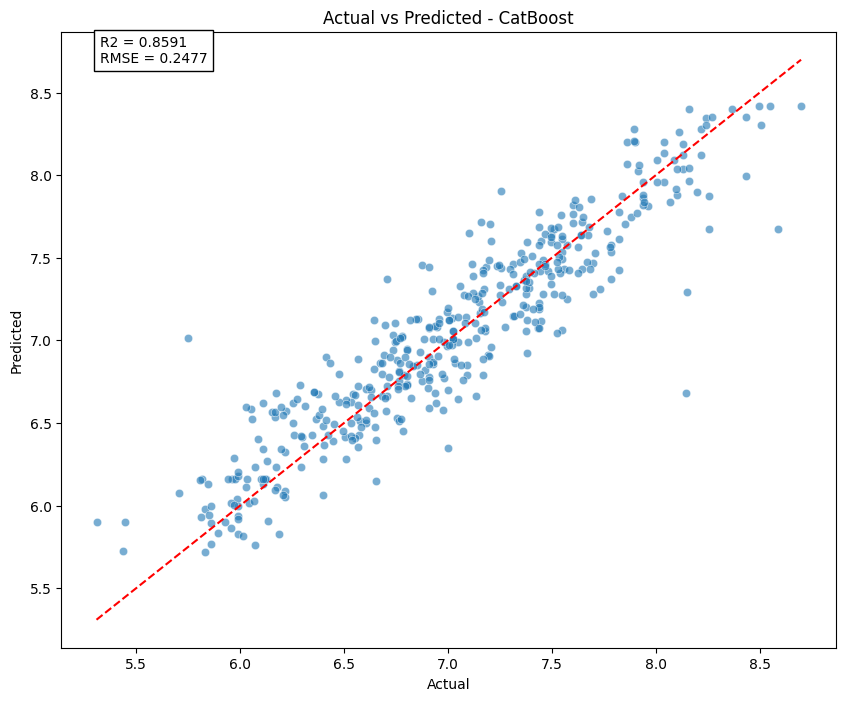

In [234]:
plt.figure(figsize=(10,8))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.text(0.05, 0.95, f'R2 = {r2_test:.4f}\nRMSE = {rmse_test:.4f}', transform=plt.gca().transAxes, bbox=dict(facecolor='white'))

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted - CatBoost')
plt.show()

##Tuning

###Ridge

In [235]:
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

ridge_param_grid = {
    'model__alpha': [0.01, 0.1, 1, 5, 10, 20, 50, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipe,
    ridge_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=-1
)

ridge_grid.fit(X_train_selected, y_train)

print('Best Ridge params:', ridge_grid.best_params_)
print('Best CV R2:', ridge_grid.best_score_)

best_ridge = ridge_grid.best_estimator_
evaluate_model('Ridge (Tuned)', X_train_selected, y_train, X_test_selected, y_test, best_ridge)

Best Ridge params: {'model__alpha': 10}
Best CV R2: 0.7875760258507144

===== Ridge (Tuned) =====
Cross Validation R2: 0.7876
Cross Validation RMSE: 0.2957
R2 Train: 0.7925
RMSE Train: 0.2934
R2 Test: 0.8053
RMSE Test: 0.2913


###XGB

In [236]:
xgb_param_grid = {
    'n_estimators': [600, 800],
    'max_depth': [5, 7],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1, tree_method='hist'),
    xgb_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

xgb_grid.fit(X_train_selected, y_train)

print('Best XGB params:', xgb_grid.best_params_)
print('Best CV R2:', xgb_grid.best_score_)

best_xgb = xgb_grid.best_estimator_
evaluate_model('XGB (Tuned)', X_train_selected, y_train, X_test_selected, y_test, best_xgb)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best XGB params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 600, 'subsample': 0.8}
Best CV R2: 0.8383574373608257

===== XGB (Tuned) =====
Cross Validation R2: 0.8384
Cross Validation RMSE: 0.2580
R2 Train: 0.9404
RMSE Train: 0.1573
R2 Test: 0.8551
RMSE Test: 0.2513


###LGBM

In [237]:
lgbm_param_grid = {
    'n_estimators': [800],
    'num_leaves': [31, 63],
    'learning_rate': [0.03, 0.05],
    'subsample': [0.8],
    'colsample_bytree': [0.8]
}

lgbm_grid = GridSearchCV(
    LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
    lgbm_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

lgbm_grid.fit(X_train_selected, y_train)

print('Best LGBM params:', lgbm_grid.best_params_)
print('Best CV R2:', lgbm_grid.best_score_)

best_lgbm = lgbm_grid.best_estimator_
evaluate_model('LGBM (Tuned)', X_train_selected, y_train, X_test_selected, y_test, best_lgbm)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best LGBM params: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'n_estimators': 800, 'num_leaves': 31, 'subsample': 0.8}
Best CV R2: 0.8322321739406202

===== LGBM (Tuned) =====
Cross Validation R2: 0.8322
Cross Validation RMSE: 0.2627
R2 Train: 0.9451
RMSE Train: 0.1509
R2 Test: 0.8489
RMSE Test: 0.2566


###CatBoost

In [238]:
cat_param_grid = {
    'iterations': [600, 800],
    'depth': [6, 8],
    'learning_rate': [0.03, 0.05],
    'l2_leaf_reg': [3, 7]
}

cat_grid = GridSearchCV(
    CatBoostRegressor(random_state=42, verbose=0),
    cat_param_grid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='r2',
    n_jobs=1,
    verbose=1
)

cat_grid.fit(X_train_selected, y_train)

print('Best CatBoost params:', cat_grid.best_params_)
print('Best CV R2:', cat_grid.best_score_)

best_cat = cat_grid.best_estimator_
evaluate_model('CatBoost (Tuned)', X_train_selected, y_train, X_test_selected, y_test, best_cat)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best CatBoost params: {'depth': 6, 'iterations': 800, 'l2_leaf_reg': 3, 'learning_rate': 0.05}
Best CV R2: 0.8384999505557855

===== CatBoost (Tuned) =====
Cross Validation R2: 0.8385
Cross Validation RMSE: 0.2575
R2 Train: 0.9264
RMSE Train: 0.1747
R2 Test: 0.8628
RMSE Test: 0.2445


In [239]:
summary_with_tuned = pd.DataFrame({
    name: {
        'Train R2': f"{values['r2_train']:.4f}",
        'Train RMSE': f"{values['rmse_train']:.4f}",
        'Test R2': f"{values['r2_test']:.4f}",
        'Test RMSE': f"{values['rmse_test']:.4f}"
    }
    for name, values in results.items()
}).T.sort_values(by='Test R2', ascending=False)

summary_with_tuned

,Train R2,Train RMSE,Test R2,Test RMSE
CatBoost (Tuned),0.9264,0.1747,0.8628,0.2445
CatBoost,0.9307,0.1695,0.8591,0.2477
XGB (Tuned),0.9404,0.1573,0.8551,0.2513
LGBM,0.9236,0.1781,0.8527,0.2534
LGBM (Tuned),0.9451,0.1509,0.8489,0.2566
XGB Regressor,0.9669,0.1172,0.8235,0.2773
Linear Regression,0.7925,0.2934,0.8054,0.2912
Ridge Regression,0.7925,0.2934,0.8054,0.2912
Ridge (Tuned),0.7925,0.2934,0.8053,0.2913
Decision Tree Regressor,0.9806,0.0896,0.6712,0.3785


In [243]:
best_model = best_cat
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cross_val_r2 = cross_val_score(best_model, X_train_selected, y_train, cv=kf, scoring='r2')
cross_val_rmse = cross_val_score(best_model, X_train_selected, y_train, cv=kf, scoring='neg_root_mean_squared_error')

print(f'Cross Validation R2: {cross_val_r2.mean():.4f}')
print(f'Cross Validation RMSE: {-cross_val_rmse.mean():.4f}')

best_model.fit(X_train_selected, y_train)
y_train_pred = best_model.predict(X_train_selected)
y_test_pred = best_model.predict(X_test_selected)

r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error((y_train), (y_train_pred)))
r2_test = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error((y_test), (y_test_pred)))

print(f'R2 Train: {r2_train:.4f}')
print(f'RMSE Train: {rmse_train:.4f}')
print(f'R2 Test: {r2_test:.4f}')
print(f'RMSE Test: {rmse_test:.4f}')

Cross Validation R2: 0.8385
Cross Validation RMSE: 0.2575
R2 Train: 0.9264
RMSE Train: 0.1747
R2 Test: 0.8628
RMSE Test: 0.2445


In [240]:
best_model_name = summary_with_tuned.index[0]
print(f"Best Model: {best_model_name}")

Best Model: CatBoost (Tuned)


In [241]:
pred = np.expm1(best_model.predict(X_test_selected))
actual = np.expm1(y_test)

mae = mean_absolute_error(actual, pred)

print(f"MAE {best_model_name}: {mae:,.0f} Euros")

MAE CatBoost (Tuned): 249 Euros


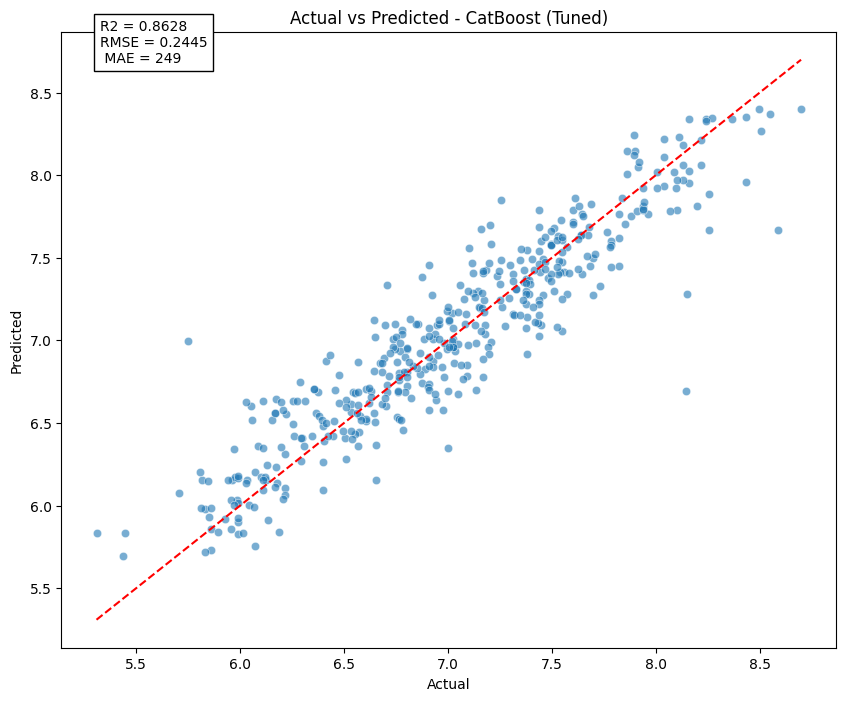

In [244]:
plt.figure(figsize=(10,8))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.text(0.05, 0.95, f'R2 = {r2_test:.4f}\nRMSE = {rmse_test:.4f}\n MAE = {mae:,.0f}', transform=plt.gca().transAxes, bbox=dict(facecolor='white'))

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Actual vs Predicted - {best_model_name}')
plt.show()

# Konklusi

Proyek ini membangun model regresi untuk memperkirakan `Final Price` laptop berdasarkan karakteristik yang tersedia pada dataset. Berdasarkan hasil yang tercatat pada notebook, CatBoost memperoleh hasil terbaik di antara model yang dibandingkan, dengan **R² test 0,8628** dan **RMSE test 0,2445**. Kedua metrik tersebut dihitung pada target yang telah ditransformasikan menggunakan `log1p`, sehingga RMSE tersebut bukan nilai kesalahan dalam satuan harga

Setelah prediksi dikembalikan ke skala harga, **MAE tercatat sekitar 249 euro**. Artinya, pada data uji yang digunakan, selisih absolut prediksi harga terhadap harga sebenarnya rata-rata sekitar 249 euro. Nilai ini memberi gambaran yang lebih mudah dipahami tentang besar kesalahan prediksi, tetapi tidak menjamin tingkat kesalahan yang sama untuk semua laptop atau untuk data dari sumber dan periode lain